# Forest Cover Type Prediction using Machine Learning

**Project by**

| Name | Roll No. |
|---|---|
| Anurag Singh | 25AI1008 |
| Ajeet Kumar Yadav | 25AI1003 |

B.Tech (AIDS) | Subject: AIML | Mini Project

---

## About the project

In this project we predict the **type of forest cover** (7 types, like Spruce/Fir, Lodgepole Pine, Aspen etc.) from the land measurements of a small 30m x 30m patch of forest. These measurements are things like elevation, slope, distance to the nearest road or water, hillshade, wilderness area and soil type.

We used the **Covertype dataset** (UCI repository). It is loaded directly with `fetch_covtype` from scikit-learn, so nothing needs to be downloaded by hand.

## What the assignment asked for and where we did it

| Requirement from the assignment | Section |
|---|---|
| Tabular dataset, more than 5000 samples, at least 10 features | 2 (we use 12,000 samples and 54 features) |
| EDA | 3 |
| Multiclass classification with a complete ML pipeline | 4 and 6 |
| K-Means (elbow curve, best k) and DBSCAN | 5 |
| Models using all features | 6 |
| Feature selection (scikit-learn techniques) | 7 |
| PCA and model development using PCA | 8 |
| Evaluation with Stratified K-Fold | 4, and used in 6 to 9 |
| Ensemble (hard voting and soft voting) | 9 |
| Final test result and conclusion | 10 and 11 |

**How to run it:** Runtime > Run all. Internet is needed the first time because the dataset gets downloaded (about 10 MB). It runs on the free Colab CPU. The cross-validation sections take a few minutes, so please wait for them.

## 1. Importing the libraries

In [1]:
# Project by: Anurag Singh (25AI1008) and Ajeet Kumar Yadav (25AI1003)
# B.Tech AIDS | AIML mini project: forest cover type prediction

import warnings
import time
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier)
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif,
                                       mutual_info_classif, RFE, SelectFromModel)
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42   # fixed seed so we get the same results every time

## 2. Loading the dataset

The full Covertype data has 581,012 rows, which is much more than we need and would make cross-validation very slow on Colab. So we take a random sample of **12,000 rows**. The sampling is *stratified*, which means every class keeps the same percentage it has in the full data. (The assignment needs more than 5000 samples, so 12,000 is fine.)

About the columns:
- **54 features in total**
  - 10 continuous ones (elevation, aspect, slope, distances, hillshade values)
  - 4 wilderness-area columns (0 or 1)
  - 40 soil-type columns (0 or 1)
- **Target:** `Cover_Type`, which has 7 classes (so this is a multiclass problem)

In [2]:
data = fetch_covtype(as_frame=True)
X_full, y_full = data.data, data.target
print("Full dataset shape:", X_full.shape)

# Stratified sample of 12,000 rows
X, _, y, _ = train_test_split(X_full, y_full, train_size=12000,
                              stratify=y_full, random_state=RANDOM_STATE)
X = X.reset_index(drop=True)
y = y.reset_index(drop=True)

df = X.copy()
df["Cover_Type"] = y

class_names = {1: "Spruce/Fir", 2: "Lodgepole Pine", 3: "Ponderosa Pine",
               4: "Cottonwood/Willow", 5: "Aspen", 6: "Douglas-fir", 7: "Krummholz"}

num_cols = list(X.columns[:10])     # 10 continuous features
wild_cols = list(X.columns[10:14])  # 4 wilderness-area flags (0/1)
soil_cols = list(X.columns[14:])    # 40 soil-type flags (0/1)

print("Sampled dataset shape:", df.shape)
print("Number of features   :", X.shape[1])
print("Number of classes    :", y.nunique())

Full dataset shape: (581012, 54)
Sampled dataset shape: (12000, 55)
Number of features   : 54
Number of classes    : 7


## 3. Exploratory Data Analysis (EDA)

Before building any model we first look at the data to understand it.

### 3.1 Basic look at the data: shape, data types, missing values, duplicates

In [3]:
display(df.head())
df.info()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Cover_Type
0,3048.0,233.0,20.0,469.0,82.0,1273.0,183.0,253.0,203.0,648.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
1,2824.0,79.0,4.0,0.0,0.0,4579.0,224.0,233.0,144.0,4751.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
2,3070.0,76.0,19.0,192.0,43.0,4234.0,240.0,202.0,85.0,2689.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2787.0,135.0,2.0,216.0,41.0,1945.0,222.0,238.0,151.0,2458.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2490.0,282.0,18.0,309.0,76.0,120.0,167.0,238.0,210.0,638.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 55 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Elevation                           12000 non-null  float64
 1   Aspect                              12000 non-null  float64
 2   Slope                               12000 non-null  float64
 3   Horizontal_Distance_To_Hydrology    12000 non-null  float64
 4   Vertical_Distance_To_Hydrology      12000 non-null  float64
 5   Horizontal_Distance_To_Roadways     12000 non-null  float64
 6   Hillshade_9am                       12000 non-null  float64
 7   Hillshade_Noon                      12000 non-null  float64
 8   Hillshade_3pm                       12000 non-null  float64
 9   Horizontal_Distance_To_Fire_Points  12000 non-null  float64
 10  Wilderness_Area_0                   12000 non-null  float64
 11  Wilderness_Area_1                   12000

In [4]:
display(df.describe().T.round(2))
print("Missing values :", int(df.isnull().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))

,count,mean,std,min,25%,50%,75%,max
Elevation,12000.0,2957.93,279.90,1876.0,2807.0,2995.0,3165.00,3856.0
Aspect,12000.0,156.32,112.14,0.0,59.0,128.0,263.00,360.0
Slope,12000.0,14.16,7.46,0.0,9.0,13.0,18.00,51.0
Horizontal_Distance_To_Hydrology,12000.0,269.74,211.73,0.0,108.0,218.0,390.00,1343.0
Vertical_Distance_To_Hydrology,12000.0,47.10,58.90,-152.0,7.0,30.0,70.00,544.0
Horizontal_Distance_To_Roadways,12000.0,2340.89,1547.88,0.0,1101.0,2003.0,3296.25,7039.0
Hillshade_9am,12000.0,212.11,27.15,0.0,198.0,218.0,231.00,254.0
Hillshade_Noon,12000.0,223.31,19.44,100.0,213.0,226.0,237.00,254.0
Hillshade_3pm,12000.0,142.55,38.42,0.0,119.0,143.0,168.00,252.0
Horizontal_Distance_To_Fire_Points,12000.0,1977.32,1325.97,0.0,1024.0,1699.0,2543.25,6930.0


Missing values : 0
Duplicate rows : 0


### 3.2 Class distribution (is the data balanced?)

We check how many samples each cover type has.

,count,percent
Cover_Type,,
Lodgepole Pine,5851,48.76
Spruce/Fir,4375,36.46
Ponderosa Pine,738,6.15
Krummholz,424,3.53
Douglas-fir,359,2.99
Aspen,196,1.63
Cottonwood/Willow,57,0.48


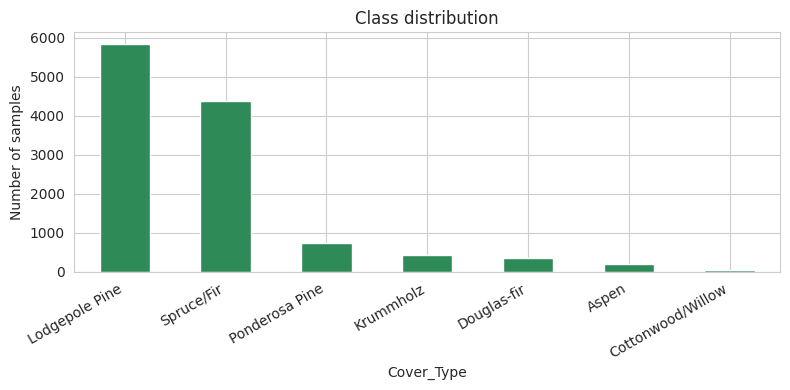

In [5]:
counts = df["Cover_Type"].map(class_names).value_counts()
summary = counts.to_frame("count")
summary["percent"] = (100 * summary["count"] / len(df)).round(2)
display(summary)

counts.plot(kind="bar", figsize=(8, 4), color="seagreen")
plt.title("Class distribution")
plt.ylabel("Number of samples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 3.3 Histograms of the continuous features

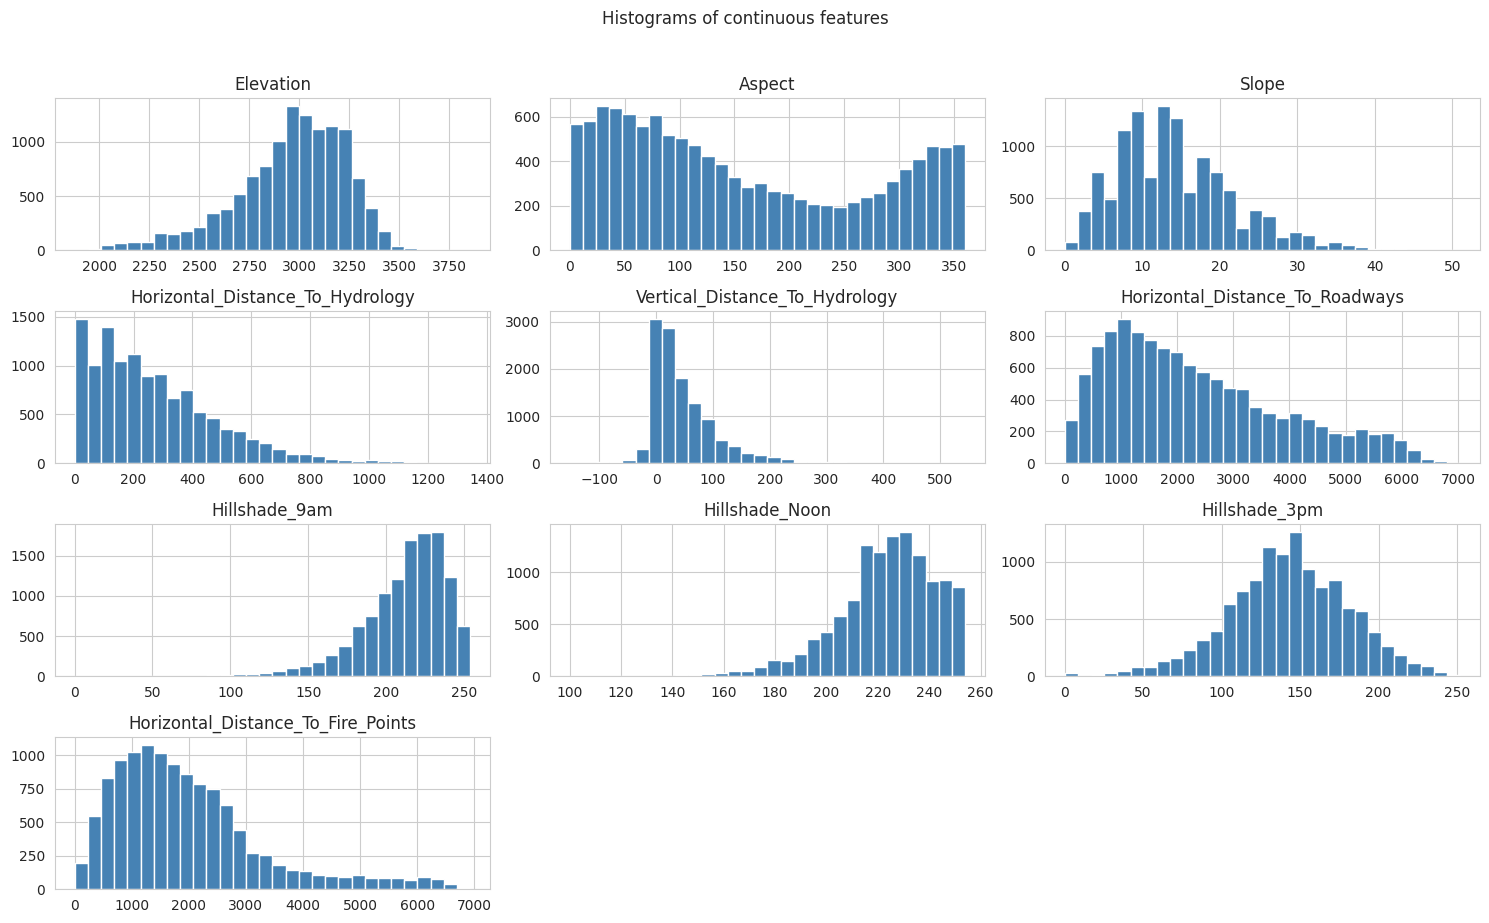

In [6]:
df[num_cols].hist(bins=30, figsize=(15, 9), color="steelblue", edgecolor="white")
plt.suptitle("Histograms of continuous features", y=1.02)
plt.tight_layout()
plt.show()

### 3.4 Outliers (using the IQR rule)

A value is counted as an outlier if it is more than 1.5 x IQR below Q1 or above Q3.

,outliers,percent
Elevation,291,2.43
Aspect,0,0.00
Slope,323,2.69
Horizontal_Distance_To_Hydrology,253,2.11
Vertical_Distance_To_Hydrology,620,5.17
Horizontal_Distance_To_Roadways,16,0.13
Hillshade_9am,371,3.09
Hillshade_Noon,295,2.46
Hillshade_3pm,167,1.39
Horizontal_Distance_To_Fire_Points,660,5.50


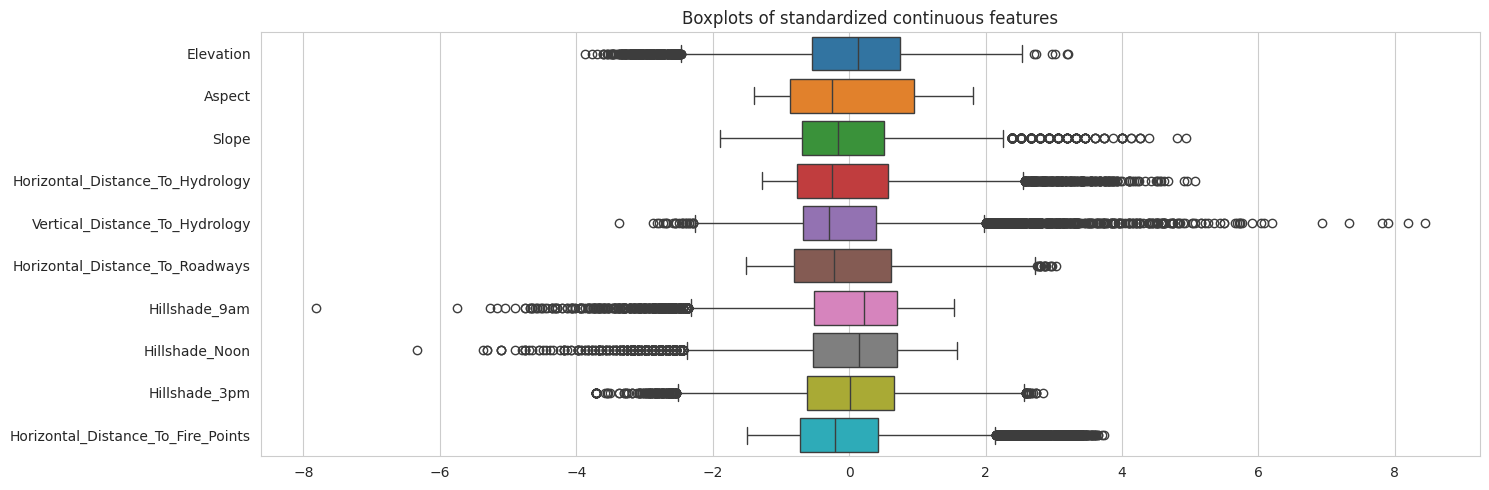

In [7]:
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (df[num_cols] < Q1 - 1.5 * IQR) | (df[num_cols] > Q3 + 1.5 * IQR)
outlier_table = pd.DataFrame({"outliers": outlier_mask.sum(),
                              "percent": (100 * outlier_mask.mean()).round(2)})
display(outlier_table)

plt.figure(figsize=(15, 5))
sns.boxplot(data=(df[num_cols] - df[num_cols].mean()) / df[num_cols].std(), orient="h")
plt.title("Boxplots of standardized continuous features")
plt.tight_layout()
plt.show()

### 3.5 Which features separate the classes?

Here we compare features across the 7 classes, and also look at correlations between features.

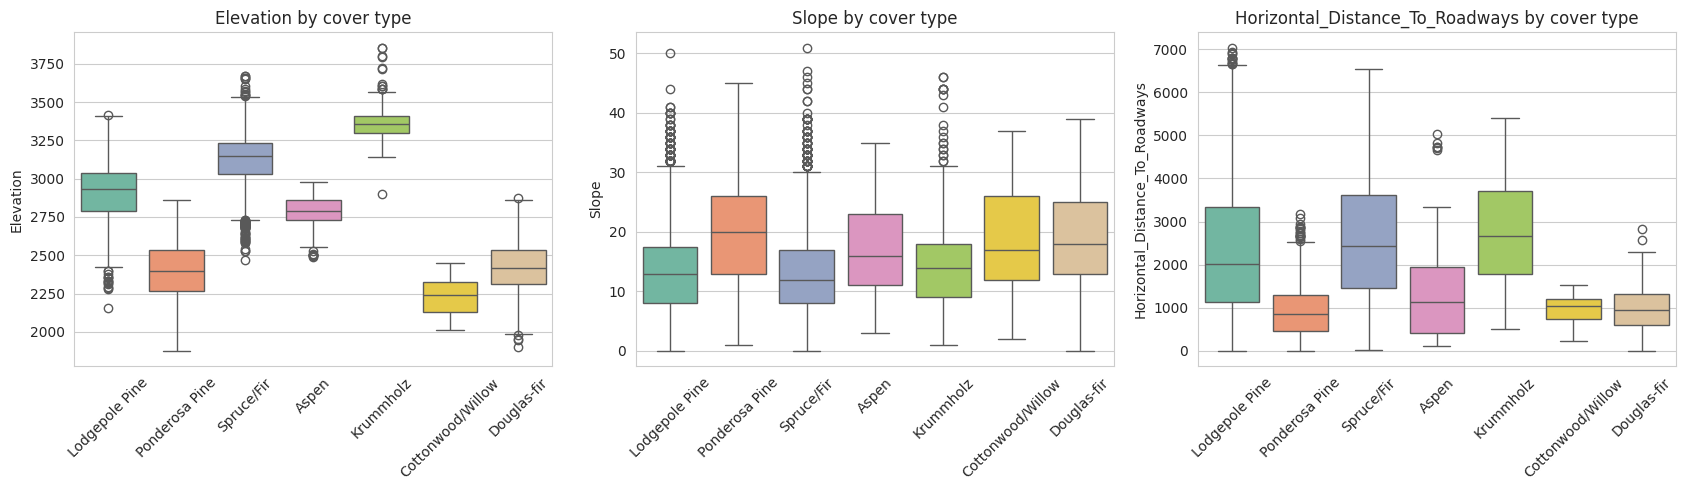

In [8]:
# Boxplots of a few continuous features, one box per class
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col in zip(axes, ["Elevation", "Slope", "Horizontal_Distance_To_Roadways"]):
    if col not in df.columns:
        col = num_cols[axes.tolist().index(ax)]
    sns.boxplot(x=df["Cover_Type"].map(class_names), y=df[col], ax=ax, palette="Set2")
    ax.set_title(col + " by cover type")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

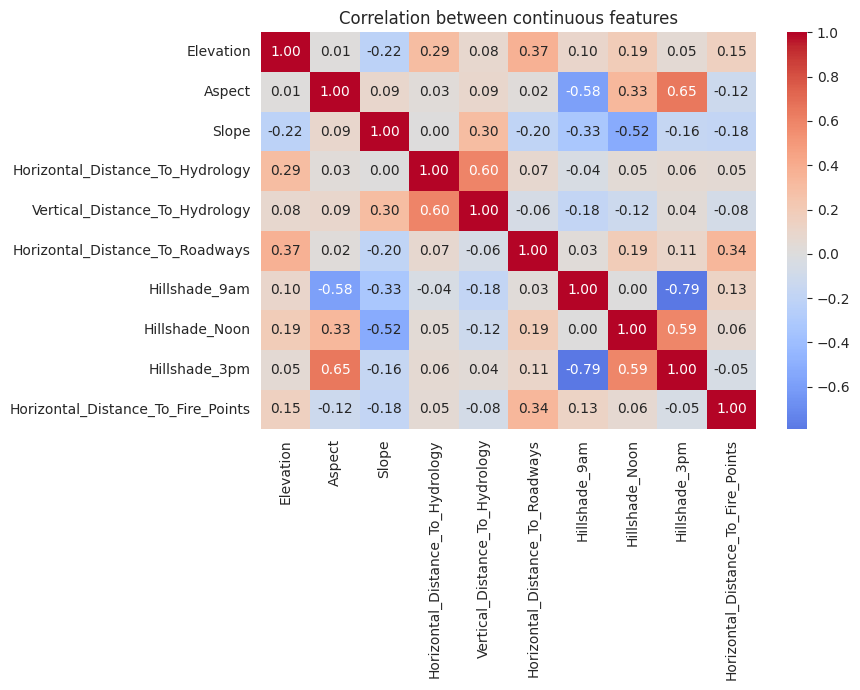

In [9]:
# Correlation heatmap of the continuous features
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between continuous features")
plt.tight_layout()
plt.show()

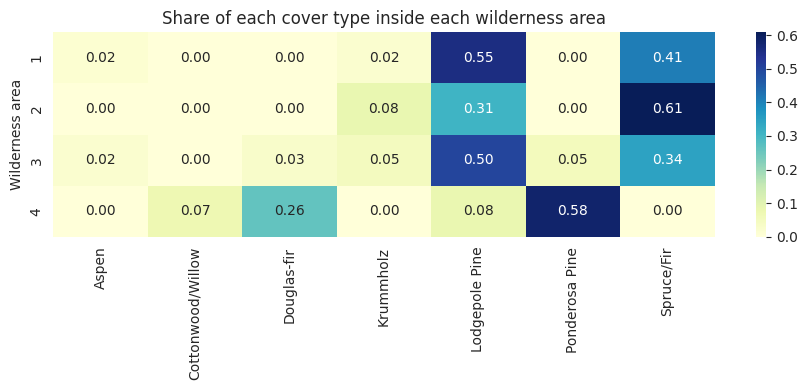

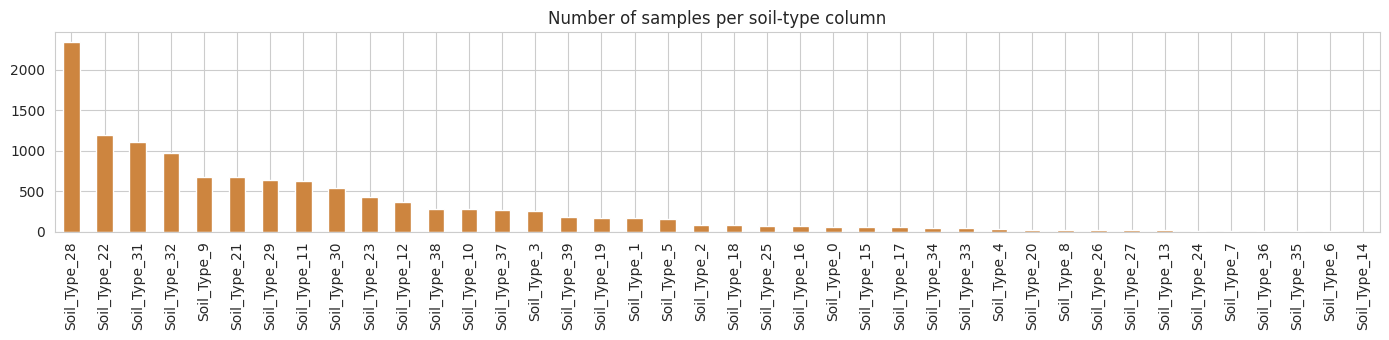

In [10]:
# Binary features: which wilderness area is each sample in, and how do classes spread over areas?
area = X[wild_cols].values.argmax(axis=1) + 1
area_vs_class = pd.crosstab(area, df["Cover_Type"].map(class_names), normalize="index")
plt.figure(figsize=(9, 4))
sns.heatmap(area_vs_class, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Share of each cover type inside each wilderness area")
plt.ylabel("Wilderness area")
plt.xlabel("")
plt.tight_layout()
plt.show()

# How often is each soil type present?
X[soil_cols].sum().sort_values(ascending=False).plot(kind="bar", figsize=(14, 3.5), color="peru")
plt.title("Number of samples per soil-type column")
plt.tight_layout()
plt.show()

### 3.6 What we found from the EDA

1. **No missing values and no cleaning needed.** The dataset is already clean, so we did not have to do any imputation.
2. **The classes are very imbalanced.** Lodgepole Pine (48.76%) and Spruce/Fir (36.46%) together make up more than 85% of the data. The smallest class, Cottonwood/Willow, has only 57 samples (0.48%). Because of this, accuracy alone can look good even if the small classes are predicted badly. So we also report **macro-F1**, which gives every class the same weight, and we use **stratified** splitting everywhere.
3. **Features are on very different scales.** Elevation is in the thousands while hillshade values are between 0 and 255 and slope is a small number. KNN, K-Means, DBSCAN and PCA are all affected by scale, so we standardize the data before using them.
4. **There are some outliers.** The highest are in `Horizontal_Distance_To_Fire_Points` (5.50%) and `Vertical_Distance_To_Hydrology` (5.17%). These look like real measurements (some places are simply far from a fire point), not mistakes, so we kept them. Tree-based models are not much affected by outliers anyway.
5. **Binary columns.** The wilderness area and soil type columns are 0/1. Many soil types are present in only a handful of samples, so we expect feature selection to remove a lot of them.

## 4. Train-test split and how we evaluate

- **Test set (20%).** We keep 20% of the data aside and do not touch it until the very end. The split is stratified, so the class percentages are the same in train and test (you can see this in the table below).
- **Stratified K-Fold (5 folds) on the training set.** All models are compared using this. A normal K-Fold can put almost none of a rare class (like Cottonwood/Willow) in some fold. Stratified K-Fold keeps the class proportions the same in every fold.
- **Pipelines.** Scaling, feature selection and PCA are put inside a scikit-learn `Pipeline`. This way they are fitted only on the training part of each fold. If we scaled or selected features on the whole data first, information from the validation fold would leak into training and the scores would look better than they really are.

The two helper functions below (`run_cv` and `show`) are used again and again in later sections to run cross-validation and to print the results table.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("\nClass share (%), train vs test:")
share = pd.DataFrame({"train": y_train.value_counts(normalize=True).sort_index() * 100,
                      "test": y_test.value_counts(normalize=True).sort_index() * 100}).round(2)
share.index = [class_names[i] for i in share.index]
display(share)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "f1_macro": "f1_macro"}

results = []    # every experiment is stored here, used for the final comparison
registry = {}   # keeps the (unfitted) pipeline of every experiment


def make_models():
    """returns new, unfitted copies of the 5 classifiers"""
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000),
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
        "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    }


def run_cv(group, name, estimator):
    """run 5-fold stratified CV for one pipeline and save the scores in `results`"""
    t0 = time.time()
    cv = cross_validate(estimator, X_train, y_train, cv=skf, scoring=SCORING, n_jobs=-1)
    row = {"Group": group, "Model": name,
           "CV Accuracy": cv["test_accuracy"].mean(),
           "CV Acc Std": cv["test_accuracy"].std(),
           "CV Macro-F1": cv["test_f1_macro"].mean(),
           "Time (s)": round(time.time() - t0, 1)}
    results.append(row)
    registry[(group, name)] = estimator
    return row


def show(prefix):
    """show saved results of one group, best macro-F1 first"""
    res = pd.DataFrame(results)
    res = res[res["Group"].str.startswith(prefix)]
    return res.sort_values("CV Macro-F1", ascending=False).reset_index(drop=True).round(4)

Train: (9600, 54)  Test: (2400, 54)

Class share (%), train vs test:


,train,test
Spruce/Fir,36.46,36.46
Lodgepole Pine,48.76,48.75
Ponderosa Pine,6.15,6.17
Cottonwood/Willow,0.48,0.46
Aspen,1.64,1.62
Douglas-fir,2.99,3.00
Krummholz,3.53,3.54


## 5. Unsupervised learning: K-Means and DBSCAN

Clustering does not use the class labels. We apply it on the **10 continuous features** (after standardizing). We left out the 0/1 columns because Euclidean distance does not make much sense on them. After clustering we compare the clusters with the real classes, just to see how much they agree.

### 5.1 K-Means: finding the best k with the elbow curve

K-Means needs us to give the number of clusters k. To choose it we run K-Means for k = 2 to 12 and plot:

- **Inertia** (sum of squared distances of points to their cluster centre). It always goes down when k increases. The "elbow" is the place where the curve stops dropping quickly, and that is our best k.
- **Silhouette score** (higher is better), which we use as a second check.

Finding the elbow by eye is a bit subjective, so the code picks it automatically as the point which is farthest from the straight line joining the first and last points of the curve.

Best k from the elbow curve     : 6
Best k from silhouette (check)  : 2


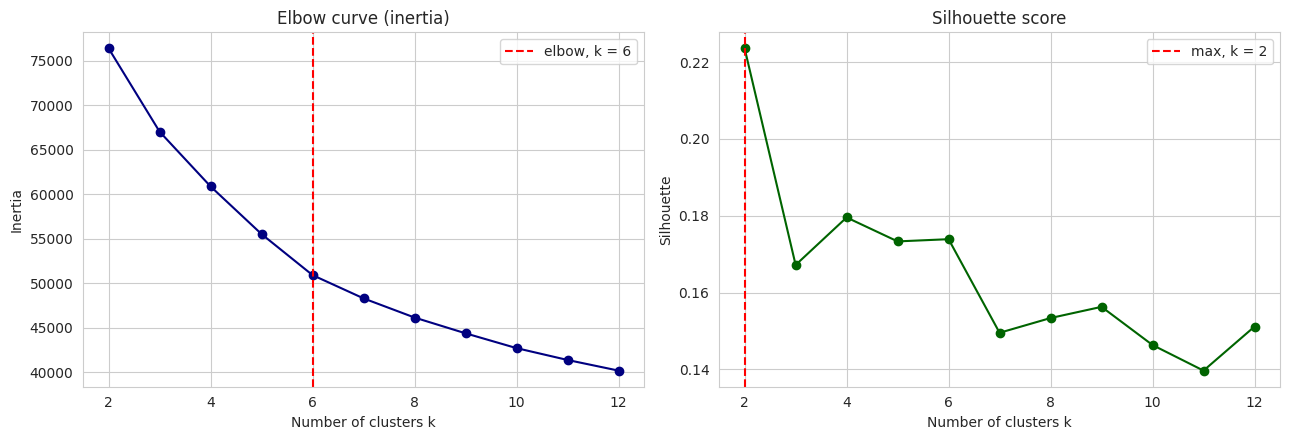

In [12]:
scaler_cl = StandardScaler()
Xc = scaler_cl.fit_transform(X_train[num_cols])   # standardized continuous features


def find_elbow(x, y):
    """position of the elbow: point farthest from the line joining first and last point"""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y - y.min()) / (y.max() - y.min())
    dx, dy = xn[-1] - xn[0], yn[-1] - yn[0]
    dist = np.abs(dx * (yn - yn[0]) - dy * (xn - xn[0])) / np.hypot(dx, dy)
    return int(np.argmax(dist))


k_values = list(range(2, 13))
inertias, sil_scores = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(Xc, km.labels_, sample_size=3000,
                                       random_state=RANDOM_STATE))

best_k = k_values[find_elbow(k_values, inertias)]
best_k_sil = k_values[int(np.argmax(sil_scores))]
print("Best k from the elbow curve     :", best_k)
print("Best k from silhouette (check)  :", best_k_sil)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(k_values, inertias, "o-", color="navy")
ax[0].axvline(best_k, color="red", linestyle="--", label=f"elbow, k = {best_k}")
ax[0].set_title("Elbow curve (inertia)")
ax[0].set_xlabel("Number of clusters k")
ax[0].set_ylabel("Inertia")
ax[0].legend()

ax[1].plot(k_values, sil_scores, "o-", color="darkgreen")
ax[1].axvline(best_k_sil, color="red", linestyle="--", label=f"max, k = {best_k_sil}")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("Number of clusters k")
ax[1].set_ylabel("Silhouette")
ax[1].legend()
plt.tight_layout()
plt.show()

K-Means (k = 6 )
  Silhouette score       : 0.1739
  Adjusted Rand Index vs true classes: 0.0197

Cluster sizes: [1363 1336 2994 2100  881  926]


Cover_Type,Aspen,Cottonwood/Willow,Douglas-fir,Krummholz,Lodgepole Pine,Ponderosa Pine,Spruce/Fir
cluster,,,,,,,
0,7,0,0,41,805,0,510
1,53,23,74,48,559,178,401
2,51,10,58,98,1561,167,1049
3,24,4,27,67,967,56,955
4,5,9,128,2,373,175,189
5,17,0,0,83,416,14,396


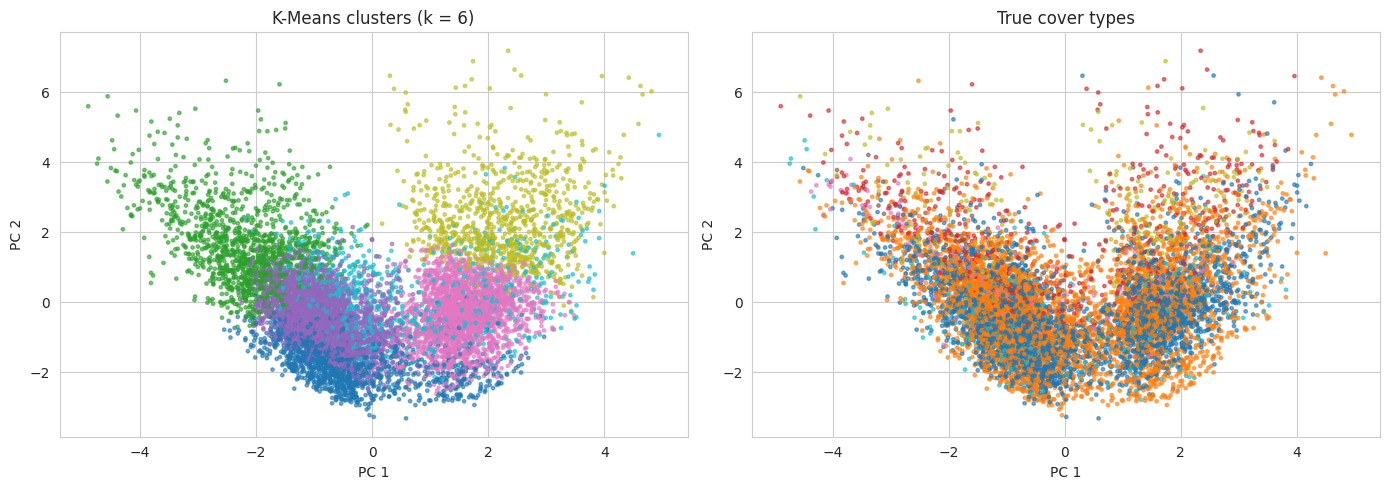

In [13]:
# Final K-Means with the k chosen by the elbow method
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
km_labels = kmeans.labels_

print("K-Means (k =", best_k, ")")
print("  Silhouette score       :", round(silhouette_score(Xc, km_labels, sample_size=3000,
                                                           random_state=RANDOM_STATE), 4))
print("  Adjusted Rand Index vs true classes:", round(adjusted_rand_score(y_train, km_labels), 4))
print("\nCluster sizes:", np.bincount(km_labels))

# Which real classes fall into which cluster?
ct = pd.crosstab(km_labels, y_train.map(class_names), rownames=["cluster"])
display(ct)

# Visualise in 2D with PCA
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xc)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(pca2[:, 0], pca2[:, 1], c=km_labels, cmap="tab10", s=6, alpha=0.6)
ax[0].set_title(f"K-Means clusters (k = {best_k})")
ax[1].scatter(pca2[:, 0], pca2[:, 1], c=y_train.values, cmap="tab10", s=6, alpha=0.6)
ax[1].set_title("True cover types")
for a in ax:
    a.set_xlabel("PC 1")
    a.set_ylabel("PC 2")
plt.tight_layout()
plt.show()

### 5.2 DBSCAN

DBSCAN groups points that are packed closely together and marks lonely points as **noise** (label -1). It has two parameters:

- `min_samples`: how many neighbours a point needs to be a core point. We took 2 x number of features = 20, which is a common rule of thumb.
- `eps`: the neighbourhood radius. We choose it with the **k-distance plot**. For every point we take the distance to its 20th nearest neighbour and sort these distances. The place where the curve bends sharply upward (the knee) is a good value for eps.

Then we also try other eps values around it to see how sensitive DBSCAN is.

min_samples = 20 | eps from k-distance knee = 1.862


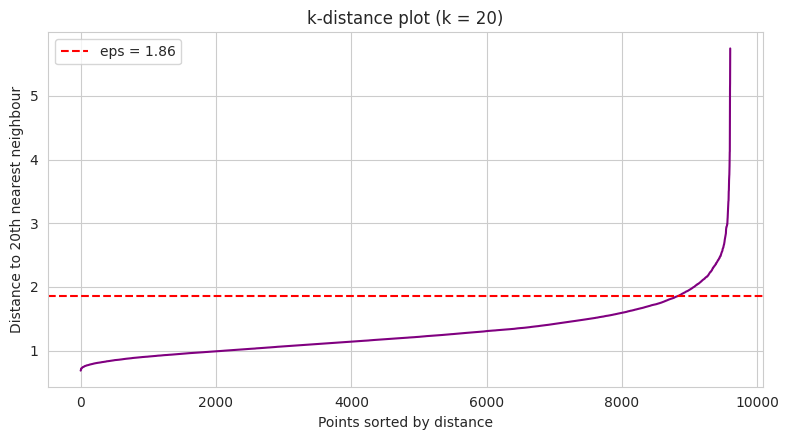

In [14]:
min_samples = 2 * len(num_cols)
nn = NearestNeighbors(n_neighbors=min_samples).fit(Xc)
distances, _ = nn.kneighbors(Xc)
kdist = np.sort(distances[:, -1])

knee_idx = find_elbow(np.arange(len(kdist)), kdist)
eps_auto = float(kdist[knee_idx])
print("min_samples =", min_samples, "| eps from k-distance knee =", round(eps_auto, 3))

plt.figure(figsize=(8, 4.5))
plt.plot(kdist, color="purple")
plt.axhline(eps_auto, color="red", linestyle="--", label=f"eps = {eps_auto:.2f}")
plt.title(f"k-distance plot (k = {min_samples})")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbour")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
def dbscan_summary(eps, min_samples):
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xc)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = 100 * np.mean(labels == -1)
    return labels, n_clusters, noise_pct


# Sensitivity of DBSCAN to eps (useful table for the report)
rows = []
for factor in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:
    e = eps_auto * factor
    _, n_c, noise = dbscan_summary(e, min_samples)
    rows.append({"eps": round(e, 3), "clusters": n_c, "noise %": round(noise, 1)})
display(pd.DataFrame(rows))

,eps,clusters,noise %
0,0.931,3,66.6
1,1.397,1,11.2
2,1.862,1,1.9
3,2.328,1,0.4
4,2.793,1,0.1
5,3.724,1,0.0


DBSCAN (eps = 1.862, min_samples = 20)
  Clusters found: 1
  Noise points  : 186 (1.9%)
  Adjusted Rand Index vs true classes: 0.0023


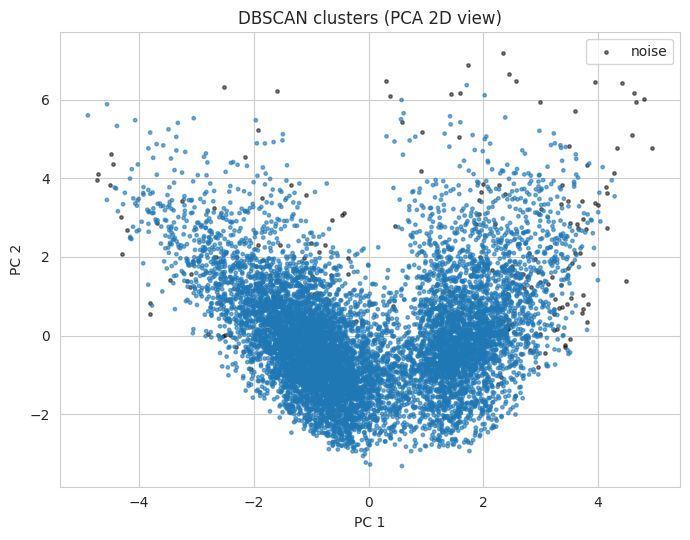

In [16]:
# final DBSCAN run with eps taken from the k-distance plot
eps = eps_auto
db_labels, n_clusters, noise_pct = dbscan_summary(eps, min_samples)
print(f"DBSCAN (eps = {eps:.3f}, min_samples = {min_samples})")
print("  Clusters found:", n_clusters)
print(f"  Noise points  : {np.sum(db_labels == -1)} ({noise_pct:.1f}%)")

core_mask = db_labels != -1
if n_clusters >= 2:
    print("  Silhouette (non-noise points):",
          round(silhouette_score(Xc[core_mask], db_labels[core_mask],
                                 sample_size=min(3000, int(core_mask.sum())),
                                 random_state=RANDOM_STATE), 4))
print("  Adjusted Rand Index vs true classes:", round(adjusted_rand_score(y_train, db_labels), 4))

noise = ~core_mask
plt.figure(figsize=(7, 5.5))
plt.scatter(pca2[noise, 0], pca2[noise, 1], c="black", s=6, alpha=0.5, label="noise")
plt.scatter(pca2[core_mask, 0], pca2[core_mask, 1], c=db_labels[core_mask],
            cmap="tab10", s=6, alpha=0.6)
plt.title("DBSCAN clusters (PCA 2D view)")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend()
plt.tight_layout()
plt.show()

### 5.3 K-Means vs DBSCAN

| | K-Means | DBSCAN |
|---|---|---|
| Number of clusters | we have to give k (found with elbow curve) | found automatically |
| Parameters | k | eps and min_samples |
| Cluster shape | roughly round | any shape |
| Outliers | every point is forced into some cluster | outliers are marked as noise (-1) |

**What we saw in our run**

- **K-Means:** the elbow curve gave **k = 6**. (The silhouette score was highest at k = 2, but the score at k = 6 is still 0.17, which means the clusters overlap a lot.) The Adjusted Rand Index with the real classes was only **0.02**.
- **DBSCAN:** with eps = 1.862 it found just **1 cluster** and 1.9% noise points. When we reduced eps to 0.931 it found 3 clusters, but 66.6% of the points became noise. The Adjusted Rand Index was **0.002**.

The Adjusted Rand Index is near 0 when the clusters are no better than random and 1 when they match the real classes perfectly. Our values are close to 0 for both algorithms. So the natural groups in the terrain measurements are **not the same as the 7 forest types**. The data does not have clearly separated dense groups (in the PCA plot the classes overlap a lot), and this is the reason we need a supervised classifier in the next sections.

## 6. Classification models using all features

Now we use the labels. We train 5 different classifiers using all 54 features. Each one is in a pipeline with a `StandardScaler`, and is evaluated with 5-fold Stratified CV:

Logistic Regression, KNN, Decision Tree, Random Forest and Histogram Gradient Boosting.

The table shows mean CV accuracy, its standard deviation across folds, mean macro-F1 and the time taken.

In [17]:
GROUP_ALL = "1. All features"

for name, model in make_models().items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    run_cv(GROUP_ALL, name, pipe)

display(show(GROUP_ALL))

,Group,Model,CV Accuracy,CV Acc Std,CV Macro-F1,Time (s)
0,1. All features,Random Forest,0.8017,0.0095,0.6353,9.3
1,1. All features,KNN,0.7411,0.0068,0.5836,0.8
2,1. All features,Decision Tree,0.7179,0.0079,0.5778,0.9
3,1. All features,Logistic Regression,0.7252,0.0106,0.5226,4.6
4,1. All features,Hist Gradient Boosting,0.7261,0.0441,0.5220,22.8


## 7. Feature selection

Not all 54 features are useful, especially many of the rare soil-type columns. We try 5 feature selection methods from `sklearn.feature_selection`:

| Type | Method | How it works |
|---|---|---|
| Filter | `VarianceThreshold` | removes features which are almost constant |
| Filter | `SelectKBest` with F-test | keeps the k features with the best ANOVA F-score against the class |
| Filter | `SelectKBest` with mutual information | same idea, but can also catch non-linear relations |
| Wrapper | `RFE` with Logistic Regression | trains the model again and again, removing the weakest features each time |
| Embedded | `SelectFromModel` with Random Forest | keeps the features that the Random Forest finds most important |

Except `VarianceThreshold`, each method keeps 20 features.

### 7.1 Which features does each method pick?

The heatmap shows which features were chosen by which method. A feature chosen by many methods is probably really important. In our run `VarianceThreshold` kept 33 of 54 features, and features like Elevation, Slope, the distance features, hillshade and some wilderness-area and soil-type columns were picked by at least 4 of the 5 methods.

VarianceThreshold                   keeps 33 of 54 features
SelectKBest F-test (k=20)           keeps 20 of 54 features
SelectKBest MutualInfo (k=20)       keeps 20 of 54 features
RFE LogReg (k=20)                   keeps 20 of 54 features
SelectFromModel RF (top 20)         keeps 20 of 54 features


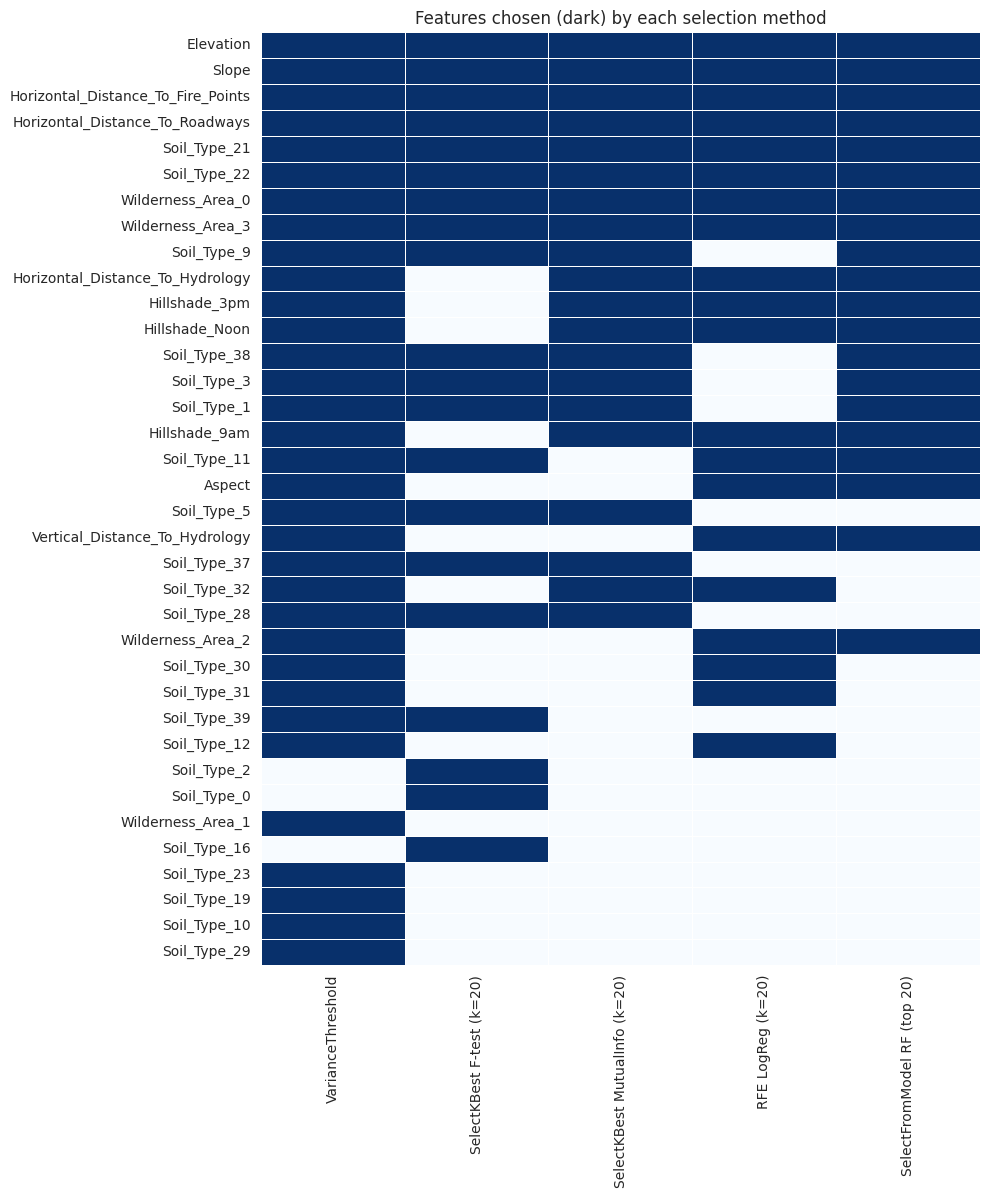

Features chosen by at least 4 of the 5 methods:
['Elevation', 'Slope', 'Horizontal_Distance_To_Fire_Points', 'Horizontal_Distance_To_Roadways', 'Soil_Type_21', 'Soil_Type_22', 'Wilderness_Area_0', 'Wilderness_Area_3', 'Soil_Type_9', 'Horizontal_Distance_To_Hydrology', 'Hillshade_3pm', 'Hillshade_Noon', 'Soil_Type_38', 'Soil_Type_3', 'Soil_Type_1', 'Hillshade_9am', 'Soil_Type_11']


In [18]:
K = 20   # number of features to keep


def make_selectors():
    """name -> (selector, apply_before_scaling)"""
    return {
        "VarianceThreshold": (VarianceThreshold(threshold=0.01), True),
        f"SelectKBest F-test (k={K})": (SelectKBest(f_classif, k=K), False),
        f"SelectKBest MutualInfo (k={K})": (
            SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=K), False),
        f"RFE LogReg (k={K})": (
            RFE(LogisticRegression(max_iter=1000), n_features_to_select=K, step=2), False),
        f"SelectFromModel RF (top {K})": (
            SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
                            max_features=K, threshold=-np.inf), False),
    }


X_train_scaled = pd.DataFrame(StandardScaler().fit_transform(X_train),
                              columns=X_train.columns, index=X_train.index)

selected = {}
for name, (sel, before_scaling) in make_selectors().items():
    sel.fit(X_train if before_scaling else X_train_scaled, y_train)
    selected[name] = X_train.columns[sel.get_support()].tolist()
    print(f"{name:35s} keeps {len(selected[name]):2d} of {X_train.shape[1]} features")

sel_matrix = pd.DataFrame({n: X_train.columns.isin(f) for n, f in selected.items()},
                          index=X_train.columns).astype(int)
sel_matrix["votes"] = sel_matrix.sum(axis=1)
top = sel_matrix[sel_matrix["votes"] > 0].sort_values("votes", ascending=False)

plt.figure(figsize=(10, 0.28 * len(top) + 2))
sns.heatmap(top.drop(columns="votes"), cmap="Blues", cbar=False, linewidths=0.5, linecolor="white")
plt.title("Features chosen (dark) by each selection method")
plt.tight_layout()
plt.show()

print("Features chosen by at least 4 of the 5 methods:")
print(top[top["votes"] >= 4].index.tolist())

### 7.2 Does feature selection help the models?

Each selector is placed inside the pipeline, so it is fitted only on the training folds (no leakage). We test it with two models, Logistic Regression (a simple linear model) and Random Forest (a tree model), and compare with the all-features scores from Section 6.

In [ ]:
for sel_name, (_, before_scaling) in make_selectors().items():
    for model_name in ["Logistic Regression", "Random Forest"]:
        sel = make_selectors()[sel_name][0]
        model = make_models()[model_name]
        if before_scaling:
            steps = [("selector", sel), ("scaler", StandardScaler()), ("model", model)]
        else:
            steps = [("scaler", StandardScaler()), ("selector", sel), ("model", model)]
        run_cv("2. " + sel_name, model_name, Pipeline(steps))

fs_table = show("2.")
display(fs_table)

# Compare with the all-features score of the same two models
base = show("1.").set_index("Model").loc[["Logistic Regression", "Random Forest"],
                                         ["CV Accuracy", "CV Macro-F1"]]
print("Reference: all 54 features")
display(base)

## 8. PCA (Principal Component Analysis)

PCA makes new features called principal components. Each one is a combination of the original features, the components are not correlated with each other, and they are ordered by how much variance of the data they hold. We can keep only the first few and drop the rest, which reduces the number of features.

PCA depends on the scale of the features, so we standardize first.

### 8.1 How much variance do the components hold?

The scree plot shows the variance of each component. The cumulative plot shows how many components we need to keep 90% and 95% of the total variance. We use 95% in the next part.

In [ ]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train_scaled)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n_95 = int(np.argmax(cum >= 0.95)) + 1
n_90 = int(np.argmax(cum >= 0.90)) + 1
print(f"Components needed for 90% variance: {n_90}")
print(f"Components needed for 95% variance: {n_95}  (out of {X_train.shape[1]})")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(range(1, len(evr) + 1), evr, color="teal")
ax[0].set_title("Scree plot (variance per component)")
ax[0].set_xlabel("Principal component")
ax[0].set_ylabel("Explained variance ratio")

ax[1].plot(range(1, len(cum) + 1), cum, "o-", markersize=3, color="darkorange")
ax[1].axhline(0.95, color="red", linestyle="--", label="95% variance")
ax[1].axvline(n_95, color="gray", linestyle="--", label=f"{n_95} components")
ax[1].set_title("Cumulative explained variance")
ax[1].set_xlabel("Number of components")
ax[1].set_ylabel("Cumulative variance")
ax[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# 2D projection of the training data, coloured by true class
proj = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_scaled)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=proj[:, 0], y=proj[:, 1], hue=y_train.map(class_names).values,
                palette="tab10", s=12, alpha=0.6)
plt.title("Training data projected on the first two principal components")
plt.xlabel("PC 1")
plt.ylabel("PC 2")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 8.2 Models built on the PCA features

Pipeline: StandardScaler, then PCA (keep 95% of the variance), then the classifier. We use the same 5 models and the same Stratified 5-fold CV, so the results can be compared directly with Section 6.

In [ ]:
GROUP_PCA = "3. PCA (95% variance)"

for name, model in make_models().items():
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                     ("model", model)])
    run_cv(GROUP_PCA, name, pipe)

pca_table = show("3.")
display(pca_table)

compare = show("1.").set_index("Model")[["CV Accuracy", "CV Macro-F1"]].join(
    pca_table.set_index("Model")[["CV Accuracy", "CV Macro-F1"]],
    lsuffix=" (all)", rsuffix=" (PCA)")
print("All features vs PCA:")
display(compare.round(4))

## 9. Ensemble learning: hard voting and soft voting

An ensemble combines several models so that the final prediction is better than a single model. We use scikit-learn's `VotingClassifier` in two ways:

- **Hard voting:** every model predicts a class and the class with the most votes wins.
- **Soft voting:** every model gives a probability for each class. The probabilities are averaged and the class with the highest average wins. This uses how confident each model is, not only its final answer.

We combine four different kinds of models: Logistic Regression, KNN, Random Forest and Histogram Gradient Boosting. We run the ensembles both on all features and on the PCA features.

In [ ]:
def make_voting(kind):
    estimators = [
        ("lr", LogisticRegression(max_iter=2000)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
        ("hgb", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]
    return VotingClassifier(estimators=estimators, voting=kind)


# Ensembles on all features
for kind in ["hard", "soft"]:
    pipe = Pipeline([("scaler", StandardScaler()), ("model", make_voting(kind))])
    run_cv("4. Ensemble (all features)", f"{kind.capitalize()} voting", pipe)

# Ensembles on PCA features
for kind in ["hard", "soft"]:
    pipe = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE)),
                     ("model", make_voting(kind))])
    run_cv("4. Ensemble (PCA)", f"{kind.capitalize()} voting", pipe)

display(show("4."))

## 10. Final comparison and test-set results

### 10.1 All experiments together

This chart and table show every model from Sections 6 to 9, ranked by cross-validated macro-F1.

In [ ]:
all_results = pd.DataFrame(results).sort_values("CV Macro-F1")
labels = all_results["Group"].str.slice(3) + " | " + all_results["Model"]
palette = dict(zip(sorted(all_results["Group"].str.slice(0, 1).unique()),
                   ["#4C72B0", "#55A868", "#C44E52", "#8172B2"]))
colors = [palette[g[0]] for g in all_results["Group"]]

fig, ax = plt.subplots(figsize=(11, 0.32 * len(all_results) + 2))
ax.barh(labels, all_results["CV Macro-F1"], color=colors)
ax.set_xlabel("CV Macro-F1")
ax.set_title("All experiments ranked by cross-validated macro-F1")
ax.set_xlim(max(0, all_results["CV Macro-F1"].min() - 0.05), 1)
plt.tight_layout()
plt.show()

print("Colours: blue = all features, green = feature selection, red = PCA, purple = ensembles")
display(pd.DataFrame(results).sort_values("CV Macro-F1", ascending=False)
        .reset_index(drop=True).round(4))

### 10.2 Best model on the test set

The model with the best CV macro-F1 is trained again on the whole training set and tested **once** on the 20% test set that we kept aside. The classification report and the confusion matrix show how it does on each class. After that we also compare hard voting, soft voting and a single Random Forest on the test set.

In [ ]:
best_row = pd.DataFrame(results).sort_values("CV Macro-F1", ascending=False).iloc[0]
print("Best by CV macro-F1:", best_row["Group"], "|", best_row["Model"])

best_model = clone(registry[(best_row["Group"], best_row["Model"])])
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print(f"\nTest accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Test macro-F1 : {f1_score(y_test, y_pred, average='macro'):.4f}\n")

target_names = [class_names[c] for c in sorted(class_names)]
print(classification_report(y_test, y_pred, target_names=target_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(8, 6.5))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, values_format=".2f", colorbar=False)
ax.set_title("Normalized confusion matrix (test set)")
plt.tight_layout()
plt.show()

In [ ]:
# Hard vs soft voting on the test set (all features)
rows = []
for kind in ["hard", "soft"]:
    pipe = Pipeline([("scaler", StandardScaler()), ("model", make_voting(kind))])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"Ensemble": f"{kind.capitalize()} voting",
                 "Test accuracy": accuracy_score(y_test, pred),
                 "Test macro-F1": f1_score(y_test, pred, average="macro")})

rf_pipe = Pipeline([("scaler", StandardScaler()), ("model", make_models()["Random Forest"])])
rf_pipe.fit(X_train, y_train)
rf_pred = rf_pipe.predict(X_test)
rows.append({"Ensemble": "Single Random Forest (reference)",
             "Test accuracy": accuracy_score(y_test, rf_pred),
             "Test macro-F1": f1_score(y_test, rf_pred, average="macro")})
display(pd.DataFrame(rows).round(4))

## 11. Summary and conclusion

**Dataset.** 12,000 samples, 54 features, 7 classes. There are no missing values, but the classes are heavily imbalanced (Lodgepole Pine 48.76% and Spruce/Fir 36.46%, while Cottonwood/Willow is only 0.48%).

**Clustering.** K-Means with the elbow method gave k = 6, with a silhouette score of 0.17 and an Adjusted Rand Index of 0.02. DBSCAN (eps = 1.862, min_samples = 20) found only 1 cluster with 1.9% noise, and its Adjusted Rand Index was 0.002. Neither algorithm recovered the real forest types, so supervised learning is needed for this data.

**Models with all features.** Random Forest was the best with a CV accuracy of 0.8017 and macro-F1 of 0.6353. After it came KNN (0.7411 / 0.5836), Decision Tree (0.7179 / 0.5778), Logistic Regression (0.7252 / 0.5226) and Hist Gradient Boosting (0.7261 / 0.5220). The linear model does worse than the tree-based Random Forest, which suggests the class boundaries are not linear. Gradient Boosting also had a much higher fold-to-fold standard deviation (0.0441) than the others.

**Feature selection.** The 5 methods agreed on a core set of features: Elevation, Slope, the distance features, hillshade and a few wilderness-area and soil-type columns. With 20 features, Logistic Regression scored ____ and Random Forest scored ____ (accuracy), against 0.7252 and 0.8017 with all 54 features. So feature selection ________________ (helped / did not help / gave about the same score).

**PCA.** ____ components were needed to keep 95% of the variance. Models on the PCA features scored ____ (best model, accuracy), compared with 0.8017 for the best model on the original features. PCA reduces the number of features, but the new components are hard to interpret.

**Ensembles.** Hard voting gave ____ and soft voting gave ____ (CV accuracy). Soft voting is expected to be a bit better because it uses the probabilities.

**Final test result.** The best pipeline got ____ accuracy and ____ macro-F1 on the 20% test set. The weakest class was ____ , which is one of the rare classes.

**What we could do to improve it.** Use more of the full 581,012 rows, tune the hyperparameters with GridSearchCV, handle the imbalance with `class_weight="balanced"` or SMOTE, and try weighted soft voting.

*Fill the ____ blanks from the outputs of Sections 7 to 10 after running those cells.*

---
*Anurag Singh (25AI1008) and Ajeet Kumar Yadav (25AI1003)*